# ORBIT: run a small world model yourself / Запусти модель мира / 运行小型世界模型

This notebook runs the **exact released v0.3 weights** using the published NumPy implementation. No account, API key, GPU or missing local modules are needed. Install `requirements-notebook.txt` in Python 3.12, then run every cell, or use `python scripts/execute_notebook.py` from the repository root.

**RU.** Все веса и нужный код теперь в репозитории. Здесь мы запускаем прежнюю модель и проверяем результат действиями. Новый рецепт обучения предиктора описан отдельно в `REPRODUCIBILITY.md`; это не восстановленный журнал первоначального обучения.

**中文。** 本 notebook 使用仓库中完整的代码和原始权重，不需要 API、账户或 GPU。新的动作预测器训练方案见 `REPRODUCIBILITY.md`，并非原始训练记录。

The original, non-standalone notebook is retained under `materials/archive/`.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "planning/model.py").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
from planning.model import load_model, scenario, rollout, PLANS, HIT
from planning.benchmark import evaluate
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)
model = load_model()
print("Encoder + predictor + probe loaded from separate NPZ files.")

Python: 3.12.14 NumPy: 2.1.3
Encoder + predictor + probe loaded from separate NPZ files.


## 1. Observe / Наблюдать / 观察

The planner sees two 24 × 24 images and a goal image. Simulator coordinates stay outside the planner; we use them later to check its choice.

Планировщик получает изображения, а не координаты и скорость. Числовое состояние симулятора понадобится только для проверки выбранного плана。规划器只接收图像；真实状态仅用于之后的检验。

In [2]:
scene = scenario(1993276268, noise=0.03)
print("Context:", scene["frames"].shape, "Goal:", scene["goal_frame"].shape)
features = model.encode(scene["frames"])
print("Two internal representations:", features.shape)

Context: (2, 576) Goal: (576,)
Two internal representations: (2, 8)


## 2. Predict and choose / Предсказать и выбрать / 预测与选择

All 27 plans are ranked by distance to goal features. The coordinate probe helps us display predictions, but does not participate in selecting the plan. This scene was deliberately selected to show a failure, not to estimate typical accuracy.

In [3]:
best, costs, predictions = model.rank(scene["frames"], scene["goal_frame"])
actions = PLANS[best]
print("Chosen actions (-1 left, 0 coast, +1 right):", actions.tolist())
print("Predicted features:", predictions.shape)
for index in np.argsort(costs)[:5]:
    print(PLANS[index].tolist(), "feature cost =", round(float(costs[index]), 6))

Chosen actions (-1 left, 0 coast, +1 right): [1, 0, 1]
Predicted features: (27, 3, 8)
[1, 0, 1] feature cost = 0.171914
[1, 0, 0] feature cost = 0.198298
[1, 0, -1] feature cost = 0.207209
[-1, 1, -1] feature cost = 0.22206
[0, 1, -1] feature cost = 0.254897


## 3. Check by executing / Проверить действием / 执行动作检验

Now the simulator executes the chosen actions. A model's own predicted cost is not the measured outcome. The oracle is a reference with privileged access to exact state and physics.

In [4]:
actual = rollout(scene["p1"], scene["v"], actions)
predicted_xy = model.decode(predictions[best])
distance = float(np.linalg.norm(actual[-1] - scene["goal"]))
all_actual = rollout(scene["p1"], scene["v"], PLANS)
oracle_distance = float(np.linalg.norm(all_actual[:, -1] - scene["goal"], axis=-1).min())
print("Predicted distance (pixels):", round(float(np.linalg.norm(predicted_xy[-1]-scene["goal"]))*23, 4))
print("Actual distance (pixels):", round(distance*23, 4), "Hit:", distance <= HIT)
print("Privileged oracle distance (pixels):", round(oracle_distance*23, 4))

Predicted distance (pixels): 1.0941
Actual distance (pixels): 3.061 Hit: False
Privileged oracle distance (pixels): 0.159


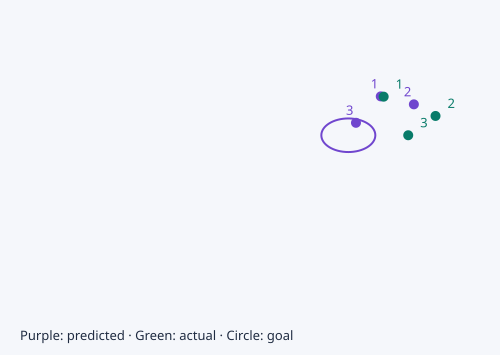

In [5]:
from IPython.display import SVG, display
# Dots are positions after each impulse; no invented continuous prediction path.
def point(p): return (25 + 450*float(p[0]), 20 + 280*float(p[1]))
svg = ['<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 500 355" role="img" aria-label="Predicted and actual positions after each action">', '<rect width="500" height="355" fill="#f5f7fb"/>']
gx, gy = point(scene["goal"])
svg.append(f'<ellipse cx="{gx}" cy="{gy}" rx="{450*HIT}" ry="{280*HIT}" fill="none" stroke="#7046ce" stroke-width="2"/>')
for positions, color, offset in [(predicted_xy, '#7046ce', -10), (actual, '#087b69', 12)]:
    for step, p in enumerate(positions, 1):
        x, y = point(p)
        svg.append(f'<circle cx="{x}" cy="{y}" r="5" fill="{color}"/><text x="{x+offset}" y="{y-8}" fill="{color}" font-family="sans-serif" font-size="13">{step}</text>')
svg.append('<text x="20" y="340" fill="#202c42" font-family="sans-serif" font-size="13">Purple: predicted · Green: actual · Circle: goal</text></svg>')
display(SVG(''.join(svg)))

## 4. A fresh small benchmark / Небольшая новая проверка / 小规模重新评测

The next cell actually evaluates 256 scenes (two evaluation seeds, one released model). Its confidence intervals describe scene sampling, not variation across training runs. These are different scenes from the historical 1,024-scene report.

Следующая ячейка действительно пересчитывает результат. Полная проверка: `python -m planning.benchmark --out reports/my-benchmark.json`. 完整评测命令如上，结果可与仓库中的报告对照。

In [6]:
small_report = evaluate(model, seeds=[70001, 70002], per_seed=128)
for name, result in small_report["aggregate"].items():
    low, high = result["hit_ci95_wilson"]
    print(f"{name:18s} hit={100*result['hit_rate']:5.1f}%  95% CI=[{100*low:.1f}, {100*high:.1f}]  distance={result['mean_distance_px']:.3f} px")

model              hit= 69.5%  95% CI=[63.6, 74.8]  distance=0.935 px
random             hit= 19.1%  95% CI=[14.8, 24.4]  distance=4.380 px
no_push            hit= 23.4%  95% CI=[18.7, 29.0]  distance=3.421 px
shuffled_actions   hit= 20.3%  95% CI=[15.8, 25.7]  distance=4.053 px
oracle             hit=100.0%  95% CI=[98.5, 100.0]  distance=0.195 px


## 5. Published larger measurements / Полные измерения / 完整评测

This cell reads the checked-in report; it does not rerun the large experiment. It separates the original browser model from three newly trained action predictors. Each predictor uses the same frozen visual encoder; these are not three independent encoder pretrainings.

In [7]:
report = json.loads((root / "reports/benchmark.json").read_text())
print("Protocol:", report["protocol"], "scenes per condition:", report["per_seed"]*len(report["seeds"]))
for name, result in report["models"].items():
    normal = result["conditions"]["normal"]["aggregate"]["model"]
    print(name, f"{100*normal['hit_rate']:.2f}% hits")

Protocol: orbit-v04-eval scenes per condition: 3072
released_v03 69.53% hits
seed-31001 71.94% hits
seed-31003 72.56% hits
seed-31005 71.91% hits


## Train and experiment / Обучение и эксперименты / 训练与实验

Install `requirements-training.txt`, then run:

```sh
python -m planning.training --config configs/train-actions.json --seed 31001 --out runs/my-seed-31001
python -m planning.benchmark --predictors runs/my-seed-31001/predictor.npz --out reports/my-comparison.json
```

The output directory must be new. Training optimizes feature prediction only, over 65,536 synthetic trajectories with a separate validation set. The visual encoder is frozen; its original pretraining recipe is unavailable. See `REPRODUCIBILITY.md`, `MODEL_CARD.md`, and `BENCHMARK.md` for the exact protocol and limitations.

**Try:** change the scene seed, change observation noise, compare predicted and actual outcomes. Weak/strong impulses in the benchmark deliberately change simulator dynamics while keeping the learned predictor fixed. No claim about real-world robotics or superiority to LLMs follows from this toy task.

**RU.** Меняйте seed и шум, сравнивайте прогноз и настоящее движение. Обучение предиктора воспроизводимо; исходное предобучение энкодера пока не восстановлено.

**中文。** 可以改变种子和噪声，对比预测与实际结果。动作预测器训练可以重跑，原始编码器的预训练过程尚未恢复。